# ISO V4 Aggregate Noise Analysis

Initial notebook to load aggregate noise output from disk and inspect available HDF5 keys.

In [2]:
from pathlib import Path
import h5py

OUTPUT_DIR = Path("/scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417")

h5_files = sorted(OUTPUT_DIR.rglob("*.h5"))
print(f"Found {len(h5_files)} HDF5 file(s) under {OUTPUT_DIR}")
for f in h5_files:
    print(f" - {f}")

if not h5_files:
    raise FileNotFoundError(f"No .h5 files found under {OUTPUT_DIR}")

Found 2 HDF5 file(s) under /scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417
 - /scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417/aggregation/noise_aggregation_f090.h5
 - /scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417/aggregation/noise_aggregation_f150.h5


In [3]:
# Use the first discovered aggregate file by default
agg_file = h5_files[0]
print(f"Reading keys from: {agg_file}")

with h5py.File(agg_file, "r") as f:
    top_level_keys = list(f.keys())

print("Top-level keys:")
for k in top_level_keys:
    print(f" - {k}")

top_level_keys

Reading keys from: /scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417/aggregation/noise_aggregation_f090.h5
Top-level keys:
 - det_ids
 - obs_ends
 - obs_ids
 - obs_starts
 - wafer_slots
 - white_noise


['det_ids', 'obs_ends', 'obs_ids', 'obs_starts', 'wafer_slots', 'white_noise']

In [4]:
import numpy as np
import pandas as pd

with h5py.File(agg_file, "r") as f:
    for key in sorted(f.keys()):
        arr = f[key][()]
        print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")
        if arr.ndim == 1 and arr.size > 0:
            sample = arr[:5]
            print(f"  sample: {sample}")

det_ids: shape=(8307676,), dtype=object
  sample: [b'sch_ufm_mv15_1712008976_0_133' b'sch_ufm_mv15_1712009120_1_010'
 b'sch_ufm_mv15_1712009120_1_068' b'sch_ufm_mv15_1712009120_1_192'
 b'sch_ufm_mv15_1712009120_1_466']
obs_ends: shape=(6027,), dtype=int64
  sample: [   368 102179 109069  89855  56631]
obs_ids: shape=(6027,), dtype=object
  sample: [b'obs_1716410327_satp1_1111101' b'obs_1716810173_satp1_1101100'
 b'obs_1716418917_satp1_1111101' b'obs_1716342543_satp1_1111101'
 b'obs_1716943505_satp1_1011100']
obs_starts: shape=(6027,), dtype=int64
  sample: [   366 101845 108725  89537  56415]
wafer_slots: shape=(8307676,), dtype=int32
  sample: [6 6 6 6 6]
white_noise: shape=(8307676,), dtype=float64
  sample: [0.00122503 0.00102201 0.00097245 0.00077052 0.00115709]


## Compute NET Array Metrics

Compute:
- Scenario 1: one NET_array per wafer-band-obsid
- Scenario 2: one NET_array per band-obsid
- Scenario 3: one NET_array per band over all wafers and obsids

Unit conversion applied to raw detector NET values:
- Raw values are in K/sqrt(Hz) and derived from Q/U-like NET
- Convert to T-like K*sqrt(s) by dividing by 2
- Convert K*sqrt(s) to uK*sqrt(s) by multiplying by 1e6

Then define typical detector NET as `NET_array * sqrt(N_det)` and build summary tables.

In [8]:
import re
import matplotlib.pyplot as plt

# Raw detector NET conversion: K/sqrt(Hz) (Q/U-derived) -> uK*sqrt(s) (T-like)
NET_CONVERSION_FACTOR = 1e6 / 2.0

def decode_array(arr):
    if arr.dtype == object:
        return np.array([x.decode() if isinstance(x, (bytes, bytearray)) else str(x) for x in arr])
    return arr.astype(str)

def compute_net_array(net_values):
    valid = net_values[np.isfinite(net_values) & (net_values > 0)]
    if valid.size == 0:
        return np.nan, 0
    net_array = 1.0 / np.sqrt(np.sum(1.0 / np.square(valid)))
    return net_array, int(valid.size)

def band_from_filename(path):
    m = re.search(r"f(\d+)", path.name)
    return f"f{m.group(1)}" if m else path.stem

scenario1_records = []  # wafer-band-obsid
scenario2_records = []  # band-obsid
scenario3_records = []  # per-band total

for agg_file in h5_files:
    band = band_from_filename(agg_file)
    print(f"Processing {agg_file.name} -> {band}")

    with h5py.File(agg_file, "r") as f:
        obs_ids = decode_array(f["obs_ids"][()])
        starts = f["obs_starts"][()]
        ends = f["obs_ends"][()]
        wafer_slots = f["wafer_slots"][()]
        white_noise_raw = f["white_noise"][()]

    # Convert detector NET to uK*sqrt(s) before all calculations
    white_noise = white_noise_raw * NET_CONVERSION_FACTOR

    all_valid = white_noise[np.isfinite(white_noise) & (white_noise > 0)]
    band_net_array, band_n_det = compute_net_array(all_valid)
    scenario3_records.append({
        "scenario": "3_per_band_total",
        "row_label": band,
        "band": band,
        "n_det": band_n_det,
        "net_array": band_net_array,
        "typ_det_net": band_net_array * np.sqrt(band_n_det) if band_n_det > 0 else np.nan,
    })

    for obs_id, s, e in zip(obs_ids, starts, ends):
        s = int(s)
        e = int(e)
        if e <= s:
            continue

        wn = white_noise[s:e]
        ws = wafer_slots[s:e]

        # Scenario 2: one NET_array per band-obsid (all wafers together)
        net_array_2, n_det_2 = compute_net_array(wn)
        if n_det_2 > 0:
            scenario2_records.append({
                "scenario": "2_per_band_obsid",
                "row_label": band,
                "band": band,
                "obs_id": obs_id,
                "n_det": n_det_2,
                "net_array": net_array_2,
                "typ_det_net": net_array_2 * np.sqrt(n_det_2),
            })

        # Scenario 1: one NET_array per wafer-band-obsid
        unique_wafers = np.unique(ws)
        for wafer in unique_wafers:
            wafer_mask = ws == wafer
            net_array_1, n_det_1 = compute_net_array(wn[wafer_mask])
            if n_det_1 == 0:
                continue
            wafer_label = f"ws{int(wafer):02d}"
            scenario1_records.append({
                "scenario": "1_per_wafer_band_obsid",
                "row_label": f"{wafer_label}-{band}",
                "wafer": wafer_label,
                "band": band,
                "obs_id": obs_id,
                "n_det": n_det_1,
                "net_array": net_array_1,
                "typ_det_net": net_array_1 * np.sqrt(n_det_1),
            })

scenario1_df = pd.DataFrame(scenario1_records)
scenario2_df = pd.DataFrame(scenario2_records)
scenario3_df = pd.DataFrame(scenario3_records)

print(f"Applied NET conversion factor: {NET_CONVERSION_FACTOR} (raw -> uK*sqrt(s))")
print("\nRow counts:")
print(f"Scenario 1 entries (wafer-band-obsid): {len(scenario1_df)}")
print(f"Scenario 2 entries (band-obsid): {len(scenario2_df)}")
print(f"Scenario 3 entries (per-band total): {len(scenario3_df)}")

Processing noise_aggregation_f090.h5 -> f090
Processing noise_aggregation_f150.h5 -> f150
Applied NET conversion factor: 500000.0 (raw -> uK*sqrt(s))

Row counts:
Scenario 1 entries (wafer-band-obsid): 11444
Scenario 2 entries (band-obsid): 11444
Scenario 3 entries (per-band total): 2


In [9]:
def summarize_distribution(df, group_cols):
    grouped = df.groupby(group_cols, dropna=False)
    summary = grouped.agg(
        median_net_array=("net_array", "median"),
        mean_net_array=("net_array", "mean"),
        mean_typ_det_net=("typ_det_net", "mean"),
        median_typ_det_net=("typ_det_net", "median"),
        n_obs=("obs_id", "nunique"),
        mean_n_det=("n_det", "mean"),
    ).reset_index()
    return summary

summary1 = summarize_distribution(scenario1_df, ["wafer", "band"]).sort_values(["wafer", "band"]).reset_index(drop=True)
summary1.insert(0, "scenario", "1_per_wafer_band")
summary1["row_label"] = summary1["wafer"] + "-" + summary1["band"]

summary2 = summarize_distribution(scenario2_df, ["band"]).sort_values(["band"]).reset_index(drop=True)
summary2.insert(0, "scenario", "2_per_band")
summary2["row_label"] = summary2["band"]

summary3 = pd.DataFrame([{
    "scenario": "3_per_band_total",
    "row_label": "all_bands",
    "median_net_array": scenario3_df["net_array"].median(),
    "mean_net_array": scenario3_df["net_array"].mean(),
    "mean_typ_det_net": scenario3_df["typ_det_net"].mean(),
    "median_typ_det_net": scenario3_df["typ_det_net"].median(),
    "n_obs": np.nan,
    "mean_n_det": scenario3_df["n_det"].mean(),
}])

summary_table = pd.concat([
    summary1[["scenario", "row_label", "median_net_array", "mean_net_array", "mean_typ_det_net", "median_typ_det_net", "n_obs", "mean_n_det"]],
    summary2[["scenario", "row_label", "median_net_array", "mean_net_array", "mean_typ_det_net", "median_typ_det_net", "n_obs", "mean_n_det"]],
    summary3[["scenario", "row_label", "median_net_array", "mean_net_array", "mean_typ_det_net", "median_typ_det_net", "n_obs", "mean_n_det"]],
], ignore_index=True)

summary_table_display = summary_table.rename(columns={
    "median_net_array": "median_net_array_uK_rt_s",
    "mean_net_array": "mean_net_array_uK_rt_s",
    "mean_typ_det_net": "mean_typ_det_net_uK_rt_s",
    "median_typ_det_net": "median_typ_det_net_uK_rt_s",
})

print("Scenario 1 rows (expect wafer x band):", len(summary1))
print("Scenario 2 rows (expect band):", len(summary2))
print("Scenario 3 rows (expect 1):", len(summary3))

display(summary_table_display)

Scenario 1 rows (expect wafer x band): 14
Scenario 2 rows (expect band): 2
Scenario 3 rows (expect 1): 1


,scenario,row_label,median_net_array_uK_rt_s,mean_net_array_uK_rt_s,mean_typ_det_net_uK_rt_s,median_typ_det_net_uK_rt_s,n_obs,mean_n_det
0,1_per_wafer_band,ws00-f090,13.717583,17.377240,260.087371,254.483505,2981.0,3.394616e+02
1,1_per_wafer_band,ws00-f150,16.658014,30.656618,356.472153,338.377846,414.0,3.958647e+02
2,1_per_wafer_band,ws01-f090,13.172531,22.956913,247.165693,237.051920,459.0,3.051547e+02
3,1_per_wafer_band,ws01-f150,11.974432,13.149178,314.885716,304.611294,2165.0,6.476864e+02
4,1_per_wafer_band,ws02-f090,14.673453,29.947698,299.818277,294.179925,893.0,3.776697e+02
5,1_per_wafer_band,ws02-f150,15.073546,61.390083,379.321566,348.320851,269.0,4.335799e+02
6,1_per_wafer_band,ws03-f090,10.561602,48.445254,249.716143,235.450580,412.0,4.051044e+02
7,1_per_wafer_band,ws03-f150,14.496727,28.159933,360.674094,351.322863,1503.0,5.315655e+02
8,1_per_wafer_band,ws04-f090,127.124287,157.070094,307.304685,278.555611,21.0,5.866667e+01
9,1_per_wafer_band,ws04-f150,13.834485,18.639520,349.558137,337.024249,771.0,5.835603e+02


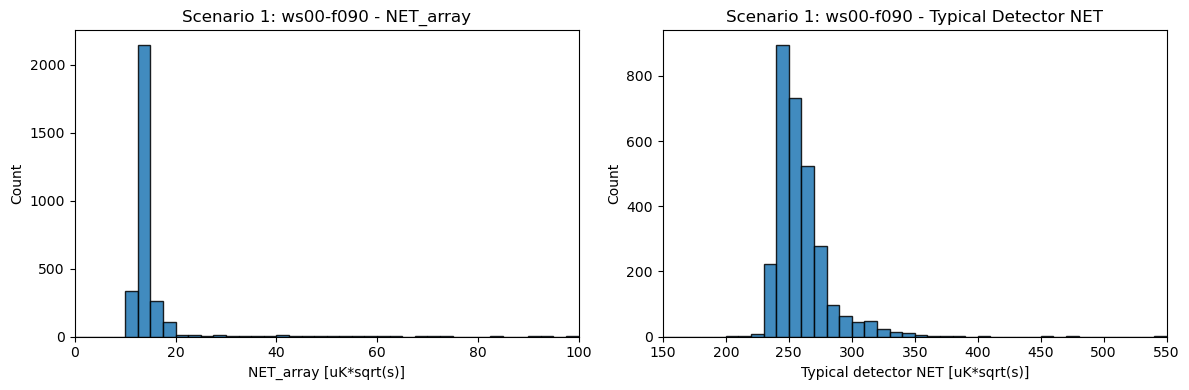

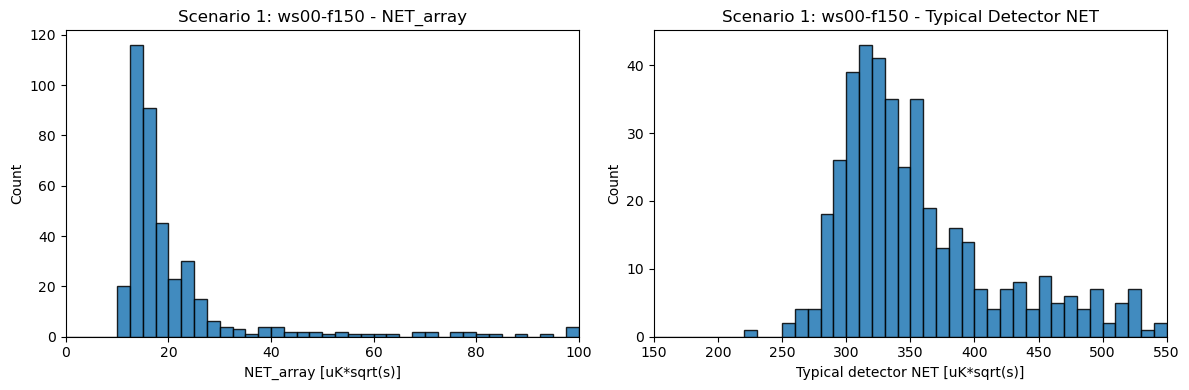

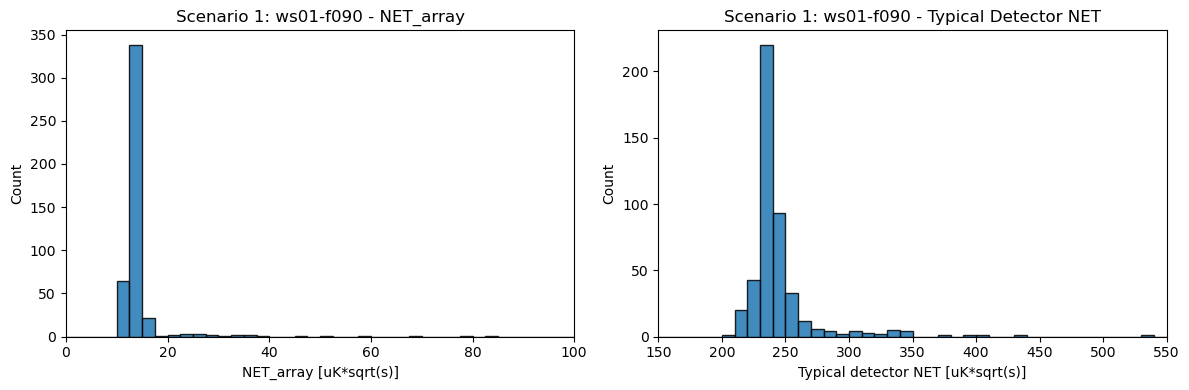

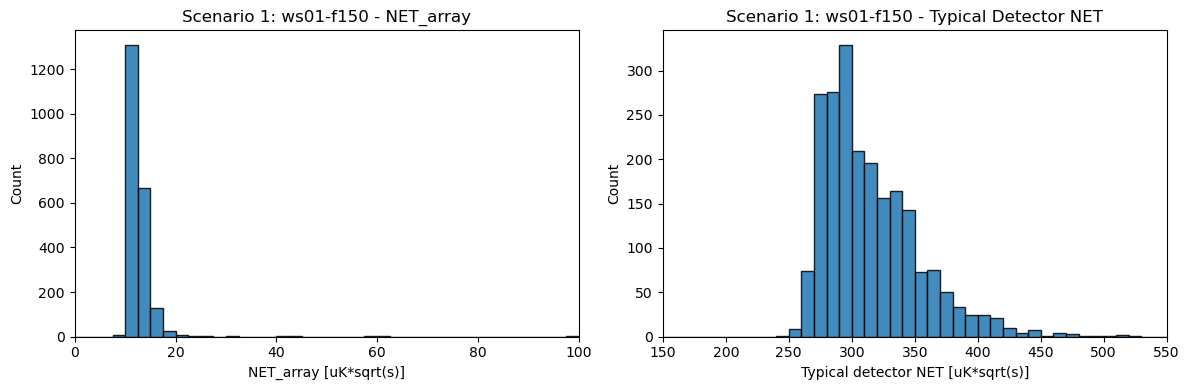

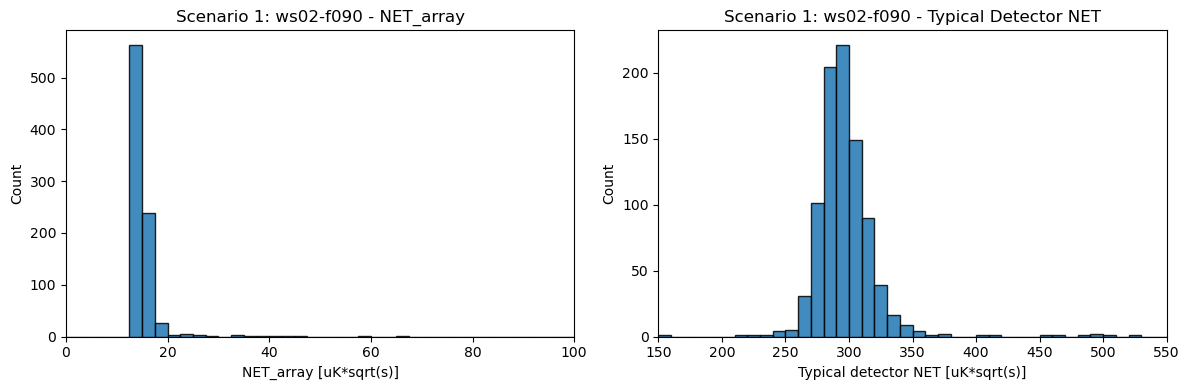

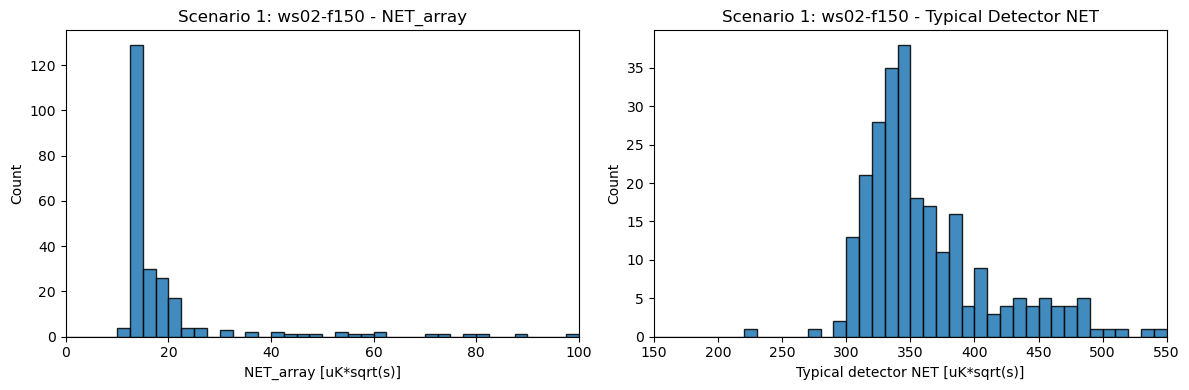

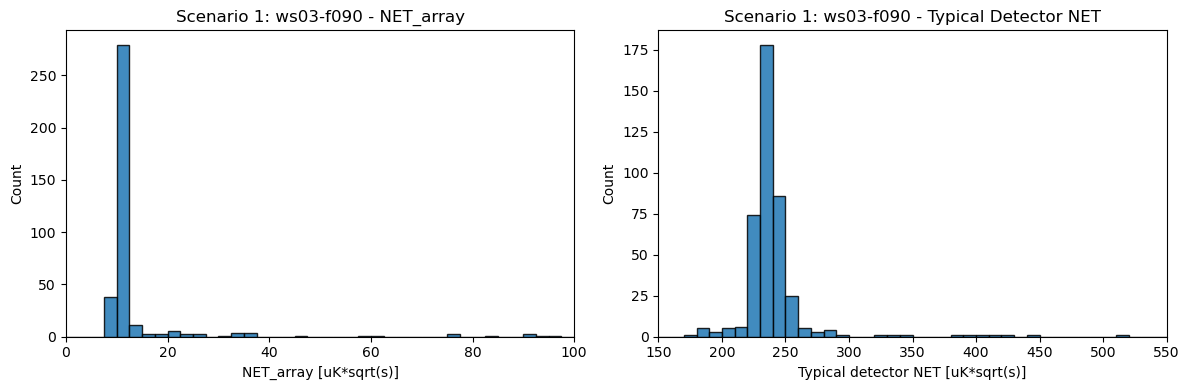

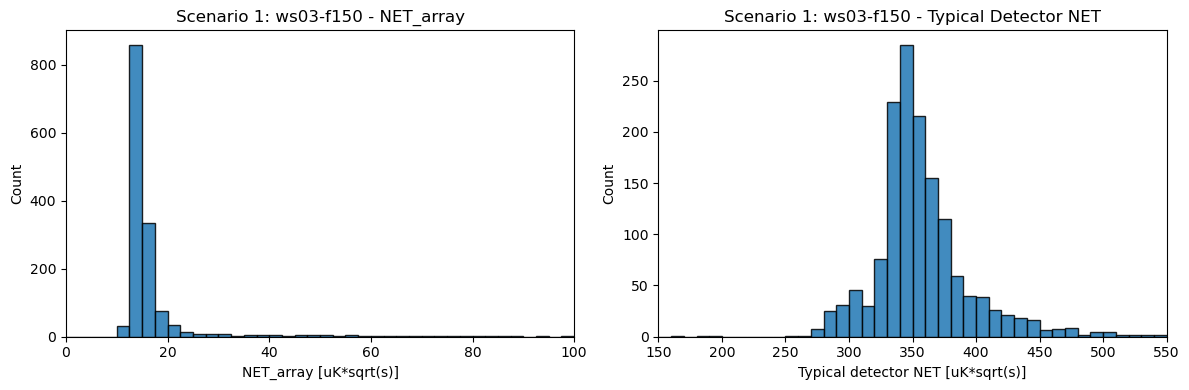

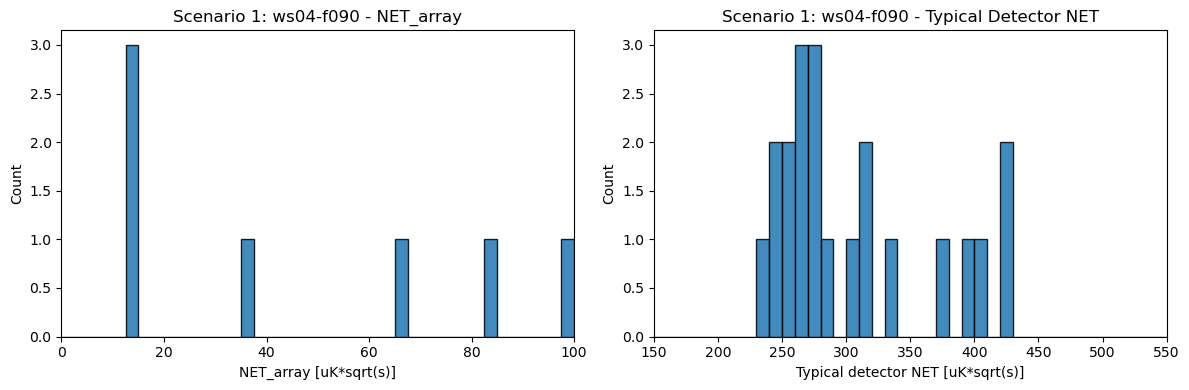

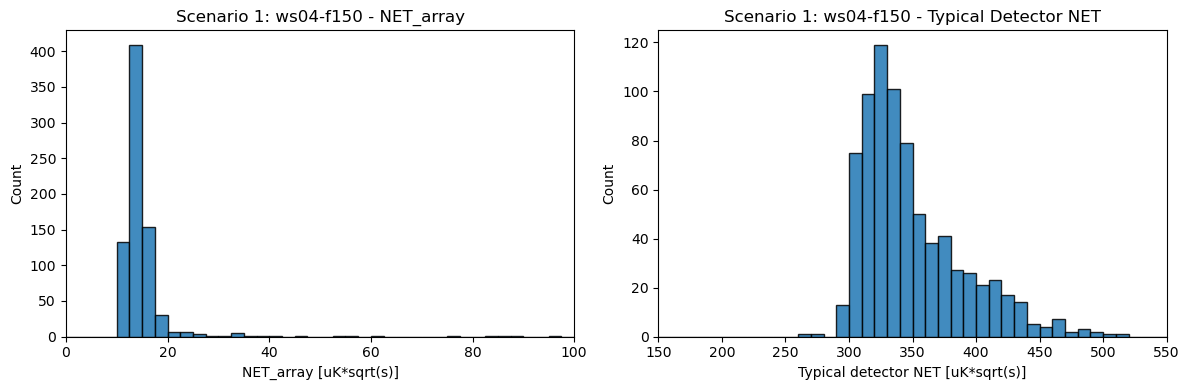

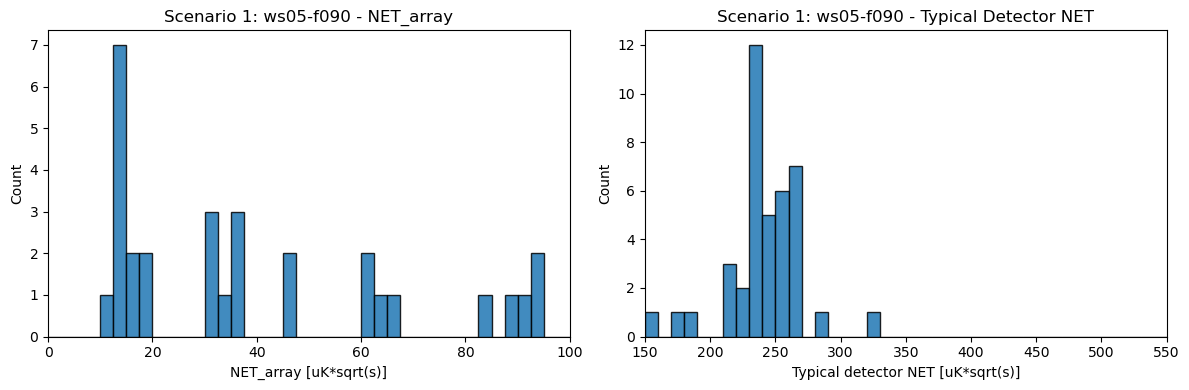

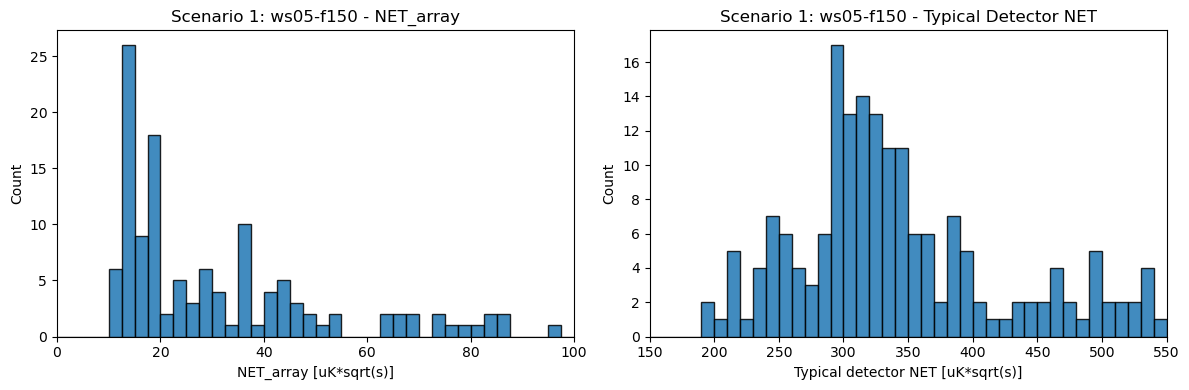

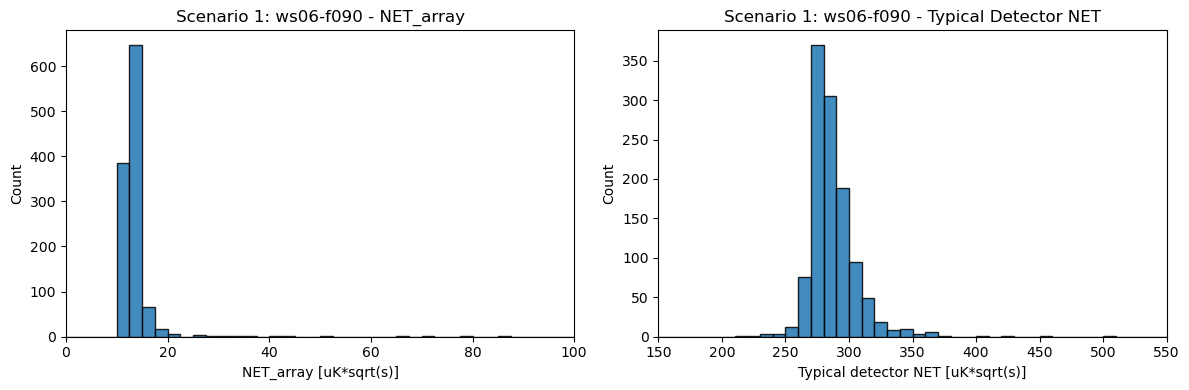

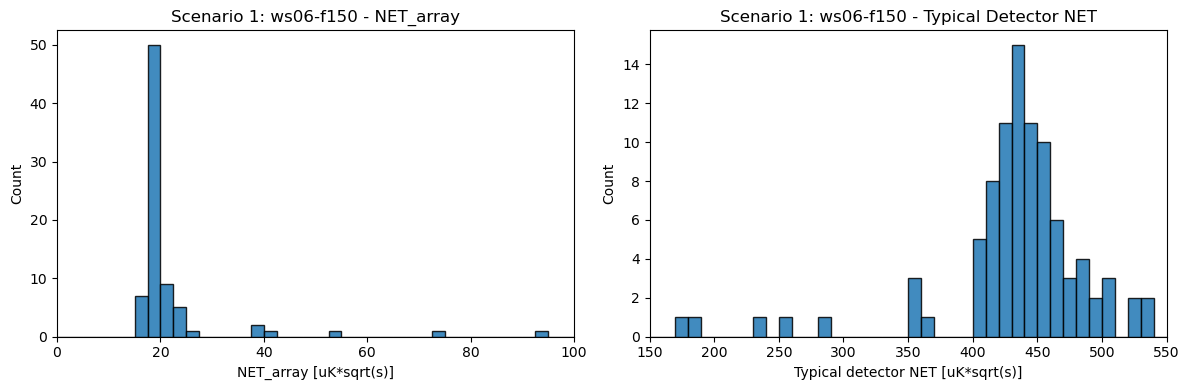

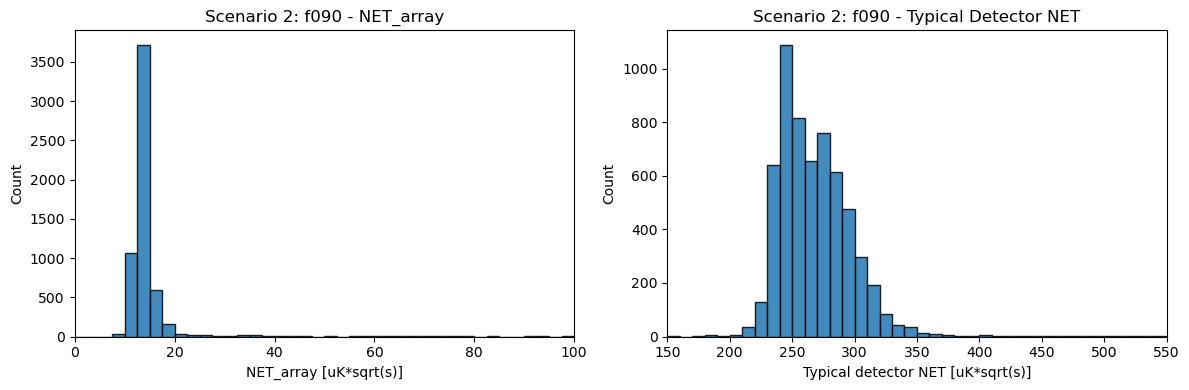

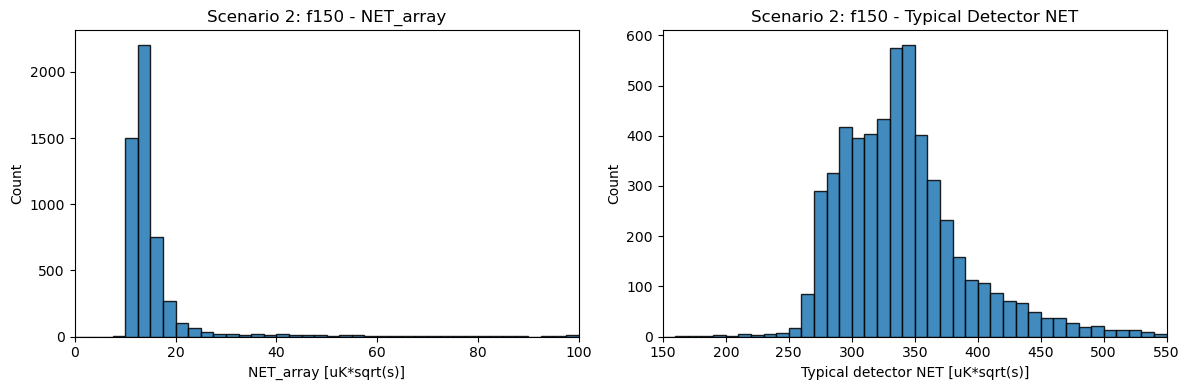

Generated histograms for all scenario 1 and scenario 2 rows.


In [11]:
def plot_distribution_pair(df, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    net_array_bins = np.linspace(0, 100, 41)
    typ_det_bins = np.linspace(150, 550, 41)

    axes[0].hist(
        df["net_array"].dropna(),
        bins=net_array_bins,
        range=(0, 100),
        alpha=0.85,
        edgecolor="black",
    )
    axes[0].set_xlim(0, 100)
    axes[0].set_title(f"{title} - NET_array")
    axes[0].set_xlabel("NET_array [uK*sqrt(s)]")
    axes[0].set_ylabel("Count")

    axes[1].hist(
        df["typ_det_net"].dropna(),
        bins=typ_det_bins,
        range=(150, 550),
        alpha=0.85,
        edgecolor="black",
    )
    axes[1].set_xlim(150, 550)
    axes[1].set_title(f"{title} - Typical Detector NET")
    axes[1].set_xlabel("Typical detector NET [uK*sqrt(s)]")
    axes[1].set_ylabel("Count")

    plt.tight_layout()
    plt.show()

# Scenario 1: one plot per wafer-band row
for _, row in summary1.iterrows():
    wafer = row["wafer"]
    band = row["band"]
    subset = scenario1_df[(scenario1_df["wafer"] == wafer) & (scenario1_df["band"] == band)]
    plot_distribution_pair(subset, f"Scenario 1: {wafer}-{band}")

# Scenario 2: one plot per band row
for _, row in summary2.iterrows():
    band = row["band"]
    subset = scenario2_df[scenario2_df["band"] == band]
    plot_distribution_pair(subset, f"Scenario 2: {band}")

print("Generated histograms for all scenario 1 and scenario 2 rows.")